# 07 · Full photos, strategy 1: a fixed rule to crop the head

Models 1 and 2 need a head crop as input. In a real photo nobody gives us the head box, so the system must find it. This notebook builds the first full system:

```
Photo → YOLOX-s finds each person → fixed rule crops the head → Model 2 (helmet?) + Model 1 (color)
```

## Step 1 · YOLOX-s (person detector)
- Official `yolox_s.onnx` model (Megvii, Apache-2.0 license), trained on COCO (80 classes; "person" is class 0). 9 million weights. We do not train it. Code: `yolox_person_detector.py`.
- **Input:** 1 × 3 × 640 × 640, in BGR order, values 0–255.
- **Letterbox:** r = min(640 / W, 640 / H). The photo is scaled by r without distortion and pasted at the top left of a grey 640 × 640 canvas.
- **Output:** 8,400 predictions, one per cell of three grids (80², 40² and 20² cells, strides of 8, 16 and 32 px). Each has a box, an "objectness" score and 80 class scores.
- **Decoding:** for cell (gx, gy) with stride s: cx = (tx + gx) · s, cy = (ty + gy) · s, w = e^tw · s, h = e^th · s. Person score = objectness × class-0 score.
- **Filter:** person score ≥ 0.3.
- **NMS** (non-maximum suppression): boxes are sorted by score, and any box that overlaps a kept box with IoU > 0.45 is dropped. IoU = intersection area / union area.

## Step 2 · Fixed rule to crop the head
For a person box (x1, y1, x2, y2), with height h = y2 − y1:
- crop side: L = 0.35 · h
- top: y1 − 0.10 · h; bottom: y1 + 0.25 · h
- centered horizontally on the person box
- resized to 224 × 224.

The rule assumes a standing person fully inside the photo, where the head is 1/7 to 1/8 of the body height. It fails for close-ups, seated people and crowds.

## Steps 3 and 4 · Model with two outputs (notebook 06), decision
- P(helmet) < 0.5 → "NO HELMET". P(helmet) ≥ 0.5 → "HELMET" + the most likely color.
- Privacy: in the example images the lower half of each head crop (the face) is blurred.

## How we measure the full system

We compare the system with the heads labeled by hand in the SHWD *test* photos (only heads with a side of 32 px or more, 6,716 heads).

- **Coverage:** a labeled head is *covered* when at least 90% of its area falls inside one of the head crops made by the system. This measures the person detector and the crop rule together.
- **Correct when covered:** we take the crop that covers the head the most and compare its decision (helmet yes or no) with the label.
- **Found and correct:** a head that is not covered counts as an error. Found and correct = covered and correct / all labeled heads. This is the percentage shown in the presentation.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from PIL import Image, ImageOps, ImageDraw, ImageFilter, ImageFont
from yolox_person_detector import detect_persons

REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
OUTPUTS, MODELS = REPO / "outputs", REPO / "models"
COLORS = ["green", "orange", "red", "transparent", "yellow"]
HELMET_THRESHOLD, MIN_SIDE = 0.5, 32

model = keras.models.load_model(MODELS / "helmet_and_color.keras")

## 1. One function per step

In [2]:
def head_box(x1, y1, x2, y2):
    # Step 2. Square of side 0.35·h, from y1 − 0.10·h to y1 + 0.25·h, centered in x
    h, cx = y2 - y1, (x1 + x2) / 2
    L = 0.35 * h
    return np.array([cx - L / 2, y1 - 0.10 * h, cx + L / 2, y1 + 0.25 * h])

def analyze(img):
    # Steps 1–4 for one photo. One row per detected person
    persons, scores = detect_persons(img)
    if not len(persons):
        return pd.DataFrame()
    heads = np.stack([head_box(*p) for p in persons])
    X = np.stack([np.asarray(img.crop(tuple(c)).resize((224, 224), Image.BILINEAR)) for c in heads]).astype("float32")
    out = model.predict(X, verbose=0)
    p_helmet = out["helmet"].ravel()
    return pd.DataFrame({"person": list(persons), "p_person": scores, "head_rect": list(heads), "p_helmet": p_helmet,
                         "helmet": p_helmet >= HELMET_THRESHOLD, "color": np.array(COLORS)[out["color"].argmax(1)],
                         "p_color": out["color"].max(1)})

def draw(img, res):
    # Blur the face (lower half of the head crop), draw the head box and its label
    img = img.copy(); d = ImageDraw.Draw(img)
    font = ImageFont.load_default(size=max(14, img.width // 45))     # readable on large photos
    width = max(3, img.width // 300)
    for _, r in res.iterrows():
        x1, y1, x2, y2 = r.head_rect
        face = tuple(int(v) for v in (x1, (y1 + y2) / 2, x2, y2))
        if face[2] > face[0] and face[3] > face[1]:
            img.paste(img.crop(face).filter(ImageFilter.GaussianBlur(float(max(2, (x2 - x1) / 10)))), face[:2])
        label, col = (f"HELMET {r.color}", "lime") if r.helmet else ("NO HELMET", "red")
        d.rectangle(tuple(r.head_rect), outline=col, width=width)
        text = f"{label} {r.p_helmet:.2f}"
        tb = d.textbbox((x1, max(0, y1 - font.size - 4)), text, font=font)
        d.rectangle(tb, fill="black")                                   # dark background so the text is readable
        d.text(tb[:2], text, fill=col, font=font)
    return img

## 2. Evaluation on the SHWD test photos

In [3]:
test_ids = (SHWD / "ImageSets/Main/test.txt").read_text().split()
rows = []
for img_id in test_ids:
    root = ET.parse(SHWD / f"Annotations/{img_id}.xml").getroot()
    labeled = [(o.findtext("name"), [int(float(o.find("bndbox").findtext(t))) for t in ("xmin", "ymin", "xmax", "ymax")])
               for o in root.iter("object") if o.findtext("name") in ("hat", "person")]
    labeled = [(c, b) for c, b in labeled if min(b[2] - b[0], b[3] - b[1]) >= MIN_SIDE]
    if not labeled:
        continue
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
    res = analyze(img)
    kind = "with some helmet" if any(c == "hat" for c, _ in labeled) else "no helmet only"
    for label, b in labeled:
        b = np.array(b, float)
        fraction, decision = 0.0, None
        if len(res):
            C = np.stack(res.head_rect)
            inter = (np.clip(np.minimum(C[:, 2], b[2]) - np.maximum(C[:, 0], b[0]), 0, None) *
                     np.clip(np.minimum(C[:, 3], b[3]) - np.maximum(C[:, 1], b[1]), 0, None))
            f = inter / ((b[2] - b[0]) * (b[3] - b[1]))
            j = f.argmax(); fraction, decision = f[j], bool(res.helmet.iloc[j])
        rows.append({"id": img_id, "kind": kind, "true_helmet": label == "hat",
                     "covered_fraction": fraction, "covered": fraction >= 0.9, "pred_helmet": decision})
ev = pd.DataFrame(rows)

ev["correct_if_covered"] = ev.pred_helmet == ev.true_helmet
ev["found_and_correct"] = ev.covered & ev.correct_if_covered
ev.to_csv(OUTPUTS / "07_test_evaluation.csv", index=False)
print(len(ev), "heads in", ev.id.nunique(), "photos")

6716 heads in 1343 photos


In [4]:
def metrics(true, covered, pred):
    true, cov = np.asarray(true, bool), np.asarray(covered, bool)
    pred_cov = np.asarray(pred, dtype=object)[cov].astype(bool)      # pred is None/NaN where nothing covers the head
    correct = np.zeros(len(true), bool)
    correct[cov] = pred_cov == true[cov]
    return {"coverage": cov.mean(),
            "sensitivity no helmet": (~pred_cov[~true[cov]]).mean() if (~true[cov]).any() else np.nan,
            "specificity helmet": pred_cov[true[cov]].mean() if true[cov].any() else np.nan,
            "found and correct": correct.mean()}

total = pd.Series(metrics(ev.true_helmet, ev.covered, ev.pred_helmet)).round(3)
pd.DataFrame({"fixed rule (07)": total}).T.to_csv(OUTPUTS / "07_comparison.csv")
total

coverage                 0.168
sensitivity no helmet    0.935
specificity helmet       0.993
found and correct        0.161
dtype: float64

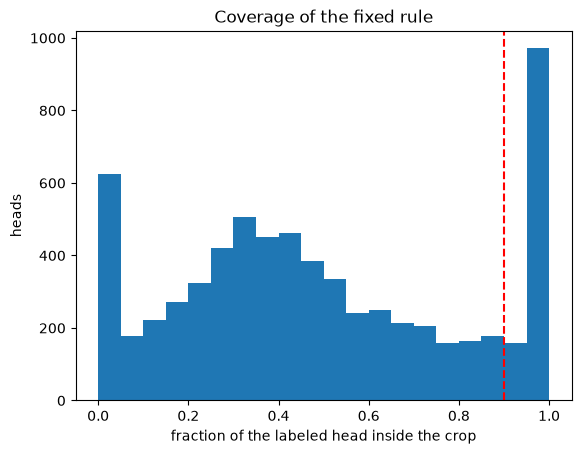

In [5]:
plt.hist(ev.covered_fraction, bins=20); plt.axvline(0.9, c="red", ls="--")
plt.xlabel("fraction of the labeled head inside the crop"); plt.ylabel("heads")
plt.title("Coverage of the fixed rule"); plt.savefig(OUTPUTS / "07_coverage.png", dpi=120); plt.show()

## 3. Why the rule works on some photos and fails on others

Blue box: the person found by YOLOX-s, with height h. Green box: the head crop of the fixed rule. We pick one test photo where the crop covers the labeled head and one where it does not.

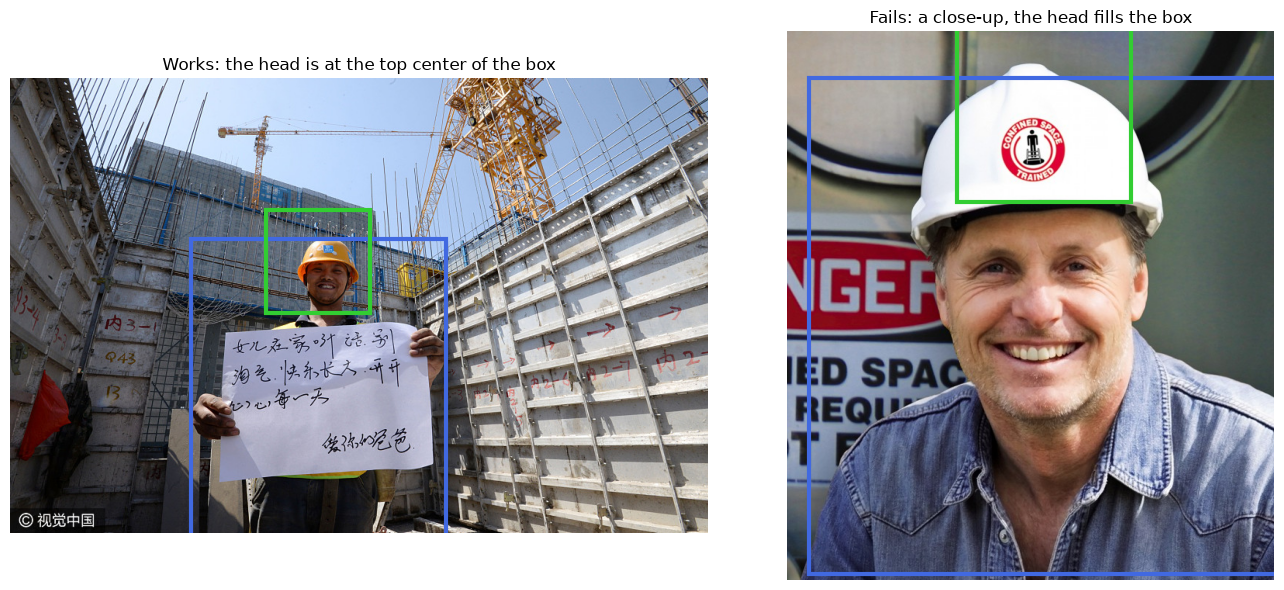

In [6]:
def one_person(img_id):
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
    persons, _ = detect_persons(img)
    return img, persons

single = ev.groupby("id").filter(lambda g: len(g) == 1)
cases = []
for title, sub in [("Works: the head is at the top center of the box", single[single.covered]),
                   ("Fails: a close-up, the head fills the box", single[single.covered_fraction < 0.5])]:
    for img_id in sub.id.sample(frac=1, random_state=0):
        img, persons = one_person(img_id)
        if len(persons) == 1:
            cases.append((title, img, persons[0])); break

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, img, p) in zip(axes, cases):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
    for (x1, y1, x2, y2), col in [(p, "royalblue"), (head_box(*p), "limegreen")]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=col, lw=3))
plt.tight_layout(); plt.savefig(OUTPUTS / "07_fixed_rule_explained.png", dpi=110); plt.show()

## 4. Examples

Green = helmet (with the color from Model 1); red = no helmet. The number is P(helmet). The face is blurred.

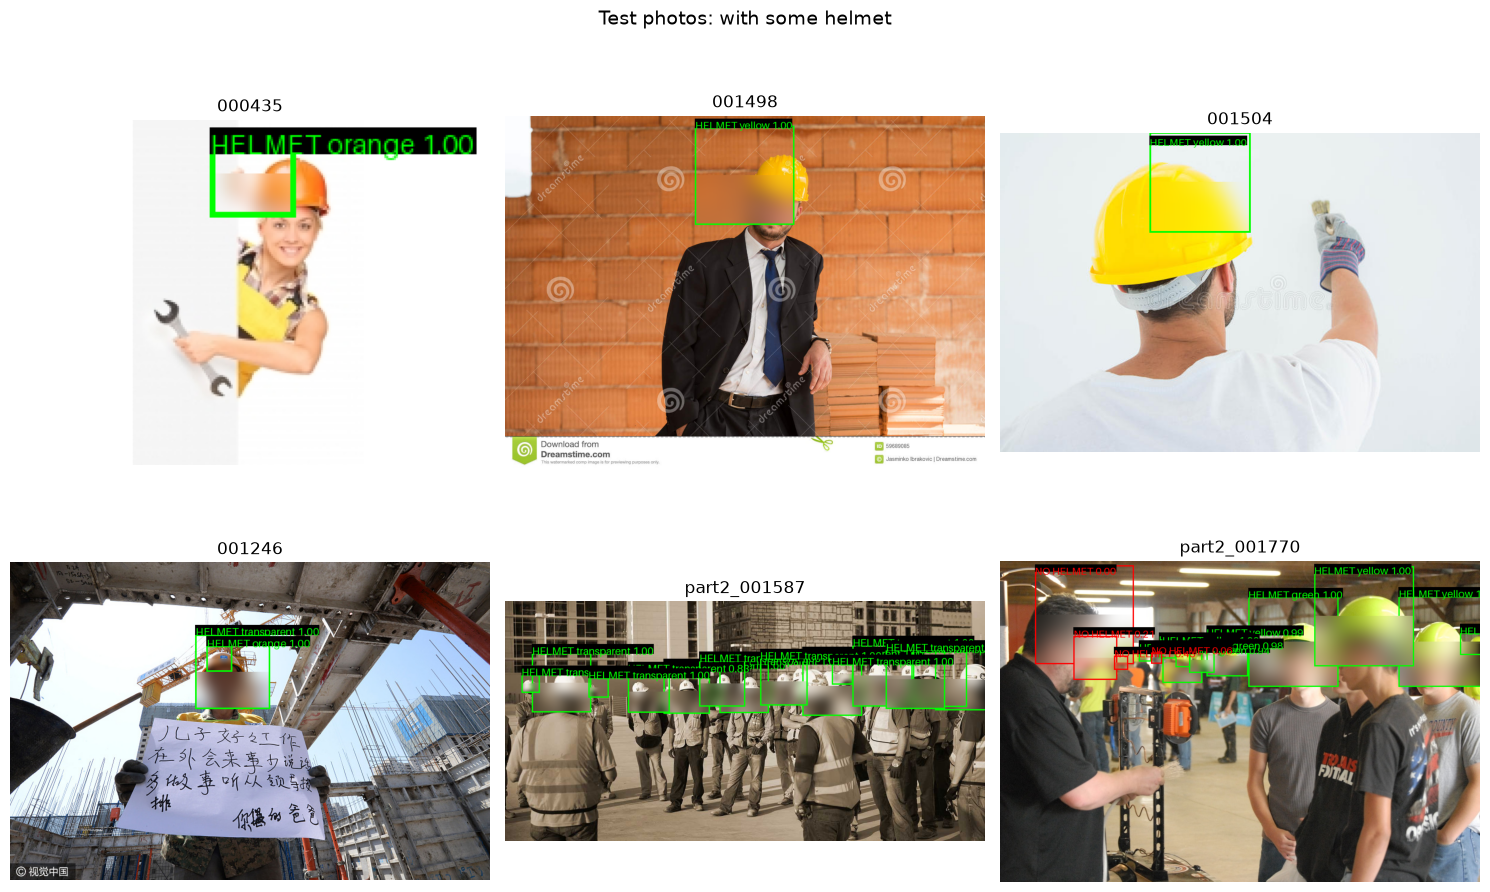

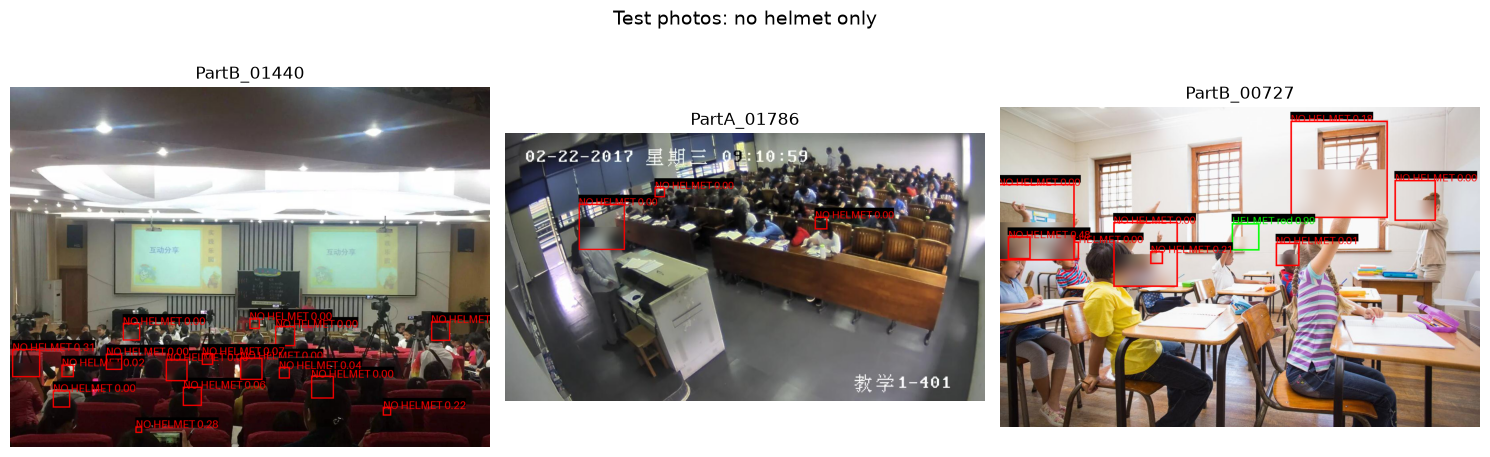

In [7]:
for kind, n, file in [("with some helmet", 6, "07_examples_helmet.png"), ("no helmet only", 3, "07_examples_no_helmet.png")]:
    examples = ev[ev.kind == kind].id.drop_duplicates().sample(n, random_state=1)
    fig, axes = plt.subplots(n // 3, 3, figsize=(15, 5 * n // 3), squeeze=False)
    for ax, img_id in zip(axes.ravel(), examples):
        img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
        ax.imshow(draw(img, analyze(img))); ax.set_title(img_id); ax.axis("off")
    fig.suptitle(f"Test photos: {kind}", fontsize=14)
    plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=100); plt.show()

## 5. What we learned
- When the crop holds the head, the helmet decision is right in about 99% of heads with a helmet.
- The weak step is **finding the head**: the rule covers only a small part of the labeled heads, so few heads are found and correct. Notebooks 08 and 09 try two other ways.